# Motivation

From the learnings in the `identifiability_and_cramer_rao` crusade, we learned how to compute the rank of the tangent space Jacobian of our model. This allows us to numerically estimate the number of learnable degrees of freedom of the model. In principle, as we are not in one of the "defective" points in the manifold, the rank should be the same. In theory, the exact number should be 


$$\min(3 N, \text{GST}_{\text{min}})$$

with $N$ the number of sequences and $\text{GST}_{\text{min}}$ the theoretical lower bound on the number of parameters after quotienting the Gauge degrees of freedom.

# Goal:

In this notebook, we want to verify a few things:

1. Compare the rank obtained for different points, i.e. the true gate set, the perturbed initialization of the optimization (and perhaps final optimized one)?

2. Verify which of these achieve the theoretical bound.

Importantly, this is only a measurement of learnability in the inifinite shots limit, without any notion of how well this are actually learned in practice. That is what the next crusade will be about, making use of the eigenvalues to compute standard deviations.

In [77]:
%load_ext autoreload
%autoreload 2

from mGST.gauge_analysis import probability_jacobian_spectrum
from mGST.utility_functions_comparisons import get_target_operators_gate_set_name, get_compressed_rep_from_mgst_output, kraus_tensor_to_mgst, get_initial_gate_set_for_optimization

from mGST.simulate import apply_noisy_kraus_tensors_to_target_gate_set, get_random_noisy_kraus_tensors_for_gate_set, generate_sequence_indices, generate_random_initial_operators
from mGST.gauge_analysis import probability_jacobian_spectrum, min_num_parameters
from mGST.visualization import plot_cost_function

import jax.numpy as jnp

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Parameters

In [63]:
seq_len_list = [1, 8, 14]
num_qubits = 2
dim = 2 ** num_qubits
state_rank = dim # max
povm_rank = dim # max
kraus_rank = 4 # start with a small rank
num_gates = 6
num_povm = dim
gate_set_name = "2QXYICZ"
noise_strength = 0.3

title_general = rf"{num_qubits}Q | $r_\mathrm{{Kraus}}$: {kraus_rank} | $r_\mathrm{{POVM}}$: {povm_rank} | $r_\mathrm{{State}}$: {state_rank}"

In [43]:
min_expected = min_num_parameters(num_qubits=num_qubits, num_gates=num_gates, state_rank=state_rank, povm_rank=povm_rank, kraus_rank=kraus_rank)
min_expected

623

# Tensors generations

In [ ]:
target_operators, gate_labels = get_target_operators_gate_set_name(gate_set_name=gate_set_name)

random_kraus_tensors = get_random_noisy_kraus_tensors_for_gate_set(
    num_gates=num_gates,
    dim=dim,
    rank_kraus=kraus_rank,
    noise_strength=noise_strength,
    seed=42
)

noisy_gate_set_superop = apply_noisy_kraus_tensors_to_target_gate_set(
    kraus_tensors_noisy=random_kraus_tensors,
    target_gate_set=target_operators,
    is_target_vectorized=True,
)

kraus_tensor_noisy, povm_psd_noisy, state_psd_noisy = get_compressed_rep_from_mgst_output(
    *noisy_gate_set_superop.values(),
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank)

kraus_target_superop = kraus_tensor_to_mgst(target_operators["kraus"])

target_gate_set_superops = {
    "kraus": kraus_target_superop,
    "povm": target_operators["povm"],
    "state": target_operators["state"],
}

kraus_tensor_target, povm_psd_target, state_psd_target = get_compressed_rep_from_mgst_output(
    *target_gate_set_superops.values(), 
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank)

target_gate_set_psd = {
    "kraus": kraus_tensor_target,
    "povm": povm_psd_target,
    "state": state_psd_target,
}

# Gathering them all in one place
noisy_gate_set_psd = {
    "kraus": kraus_tensor_noisy,
    "povm": povm_psd_noisy,
    "state": state_psd_noisy,
}

spam_depolarization = 1e-2

init_gate_set_psd = get_initial_gate_set_for_optimization(
    target_superops=target_gate_set_superops,
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank,
    spam_depolarization=spam_depolarization,
    project_kraus_to_isometry=True, # because it is max rank, even false would return an isometry
)


In [98]:
noisy_gate_set_psd

kraus_deficient = noisy_gate_set_psd["kraus"].copy()
kraus_padded = jnp.pad(kraus_deficient, ((0, 0), (0, 4), (0, 0), (0, 0)))
rank_deficient_gate_set_psd = {
    "kraus": kraus_padded,
    "povm": noisy_gate_set_psd["povm"].copy(),
    "state": noisy_gate_set_psd["state"].copy()
}

In [82]:
random_gate_set_psd = generate_random_initial_operators(
    num_gates=num_gates,
    dim=dim,
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank
)

# Compute ranks

In [13]:
# here we can define a helper function to help us compute the rank given a collection of sequences
number_of_sequences_list = [50, 100, 150, 200, 205, 208, 210, 215, 250, 300, 400]
num_shots = 1000
seq_len_list = [1, 8, 14]

In [32]:
def compute_results_for_number_of_sequences(num_sequences, gate_set_psd:dict[str, jnp.ndarray], seq_len_list: list, num_shots: int | None = None):
    kraus_tensor = gate_set_psd["kraus"]
    povm_psd = gate_set_psd["povm"]
    state_psd = gate_set_psd["state"]
    num_gates = kraus_tensor.shape[0]
    
    indices = generate_sequence_indices(num_gates=num_gates, num_circuits=num_sequences, seq_len_list=seq_len_list)["gate_indices_with_negs"]
    result_idx = probability_jacobian_spectrum(kraus_tensor, povm_psd, state_psd, indices_list=indices, num_shots=num_shots)
    return result_idx

def compute_results_for_all_number_of_sequences(number_of_sequences_list, gate_set_psd:dict[str, jnp.ndarray], seq_len_list, num_shots:int|None = None):
    results = []
    for i, num_sequences in enumerate(number_of_sequences_list):
        print(f"Computing results for {num_sequences} sequences... ({i+1}/{len(number_of_sequences_list)})")
        result_idx = compute_results_for_number_of_sequences(num_sequences, gate_set_psd, seq_len_list, num_shots)
        results.append(result_idx)
    return results

In [19]:
results_true_gate_set_1000_shots = compute_results_for_all_number_of_sequences(number_of_sequences_list=number_of_sequences_list, gate_set_psd=noisy_gate_set_psd, seq_len_list=seq_len_list, num_shots=num_shots)

Computing results for 50 sequences... (1/11)
Computing results for 100 sequences... (2/11)
Computing results for 150 sequences... (3/11)
Computing results for 200 sequences... (4/11)
Computing results for 205 sequences... (5/11)
Computing results for 208 sequences... (6/11)
Computing results for 210 sequences... (7/11)
Computing results for 215 sequences... (8/11)
Computing results for 250 sequences... (9/11)
Computing results for 300 sequences... (10/11)
Computing results for 400 sequences... (11/11)


In [33]:
results_unitary_gate_set_1000_shots = compute_results_for_all_number_of_sequences(number_of_sequences_list=number_of_sequences_list, gate_set_psd=target_gate_set_psd, seq_len_list=seq_len_list)

Computing results for 50 sequences... (1/11)
Computing results for 100 sequences... (2/11)
Computing results for 150 sequences... (3/11)
Computing results for 200 sequences... (4/11)
Computing results for 205 sequences... (5/11)
Computing results for 208 sequences... (6/11)
Computing results for 210 sequences... (7/11)
Computing results for 215 sequences... (8/11)
Computing results for 250 sequences... (9/11)
Computing results for 300 sequences... (10/11)
Computing results for 400 sequences... (11/11)


In [71]:
results_random_gate_set_1000_shots = compute_results_for_all_number_of_sequences(number_of_sequences_list=number_of_sequences_list, gate_set_psd=random_gate_set_psd, seq_len_list=seq_len_list, num_shots=num_shots)

Computing results for 50 sequences... (1/11)
Computing results for 100 sequences... (2/11)
Computing results for 150 sequences... (3/11)
Computing results for 200 sequences... (4/11)
Computing results for 205 sequences... (5/11)
Computing results for 208 sequences... (6/11)
Computing results for 210 sequences... (7/11)
Computing results for 215 sequences... (8/11)
Computing results for 250 sequences... (9/11)
Computing results for 300 sequences... (10/11)
Computing results for 400 sequences... (11/11)


In [79]:
results_init_gate_set_1000_shots = compute_results_for_all_number_of_sequences(number_of_sequences_list=number_of_sequences_list, gate_set_psd=init_gate_set_psd, seq_len_list=seq_len_list, num_shots=num_shots)

Computing results for 50 sequences... (1/11)
Computing results for 100 sequences... (2/11)
Computing results for 150 sequences... (3/11)
Computing results for 200 sequences... (4/11)
Computing results for 205 sequences... (5/11)
Computing results for 208 sequences... (6/11)
Computing results for 210 sequences... (7/11)
Computing results for 215 sequences... (8/11)
Computing results for 250 sequences... (9/11)
Computing results for 300 sequences... (10/11)
Computing results for 400 sequences... (11/11)


In [99]:
results_rank_defficient_gate_set_1000_shots = compute_results_for_all_number_of_sequences(number_of_sequences_list=number_of_sequences_list, gate_set_psd=rank_deficient_gate_set_psd, seq_len_list=seq_len_list, num_shots=num_shots)

Computing results for 50 sequences... (1/11)
Computing results for 100 sequences... (2/11)
Computing results for 150 sequences... (3/11)
Computing results for 200 sequences... (4/11)
Computing results for 205 sequences... (5/11)
Computing results for 208 sequences... (6/11)
Computing results for 210 sequences... (7/11)
Computing results for 215 sequences... (8/11)
Computing results for 250 sequences... (9/11)
Computing results for 300 sequences... (10/11)
Computing results for 400 sequences... (11/11)


In [100]:
ranks_true_gate_set_1000_shots = [result["rank"] for result in results_true_gate_set_1000_shots]
ranks_unitary_gate_set_1000_shots = [result["rank"] for result in results_unitary_gate_set_1000_shots]
ranks_random_gate_set_1000_shots = [result["rank"] for result in results_random_gate_set_1000_shots]
ranks_init_gate_set_1000_shots = [result["rank"] for result in results_init_gate_set_1000_shots]
ranks_rank_deficient_gate_set_1000_shots = [result["rank"] for result in results_rank_defficient_gate_set_1000_shots]

ranks_expected = [min(3 * num_sequences, min_expected + 1) for num_sequences in number_of_sequences_list]

# Visualization

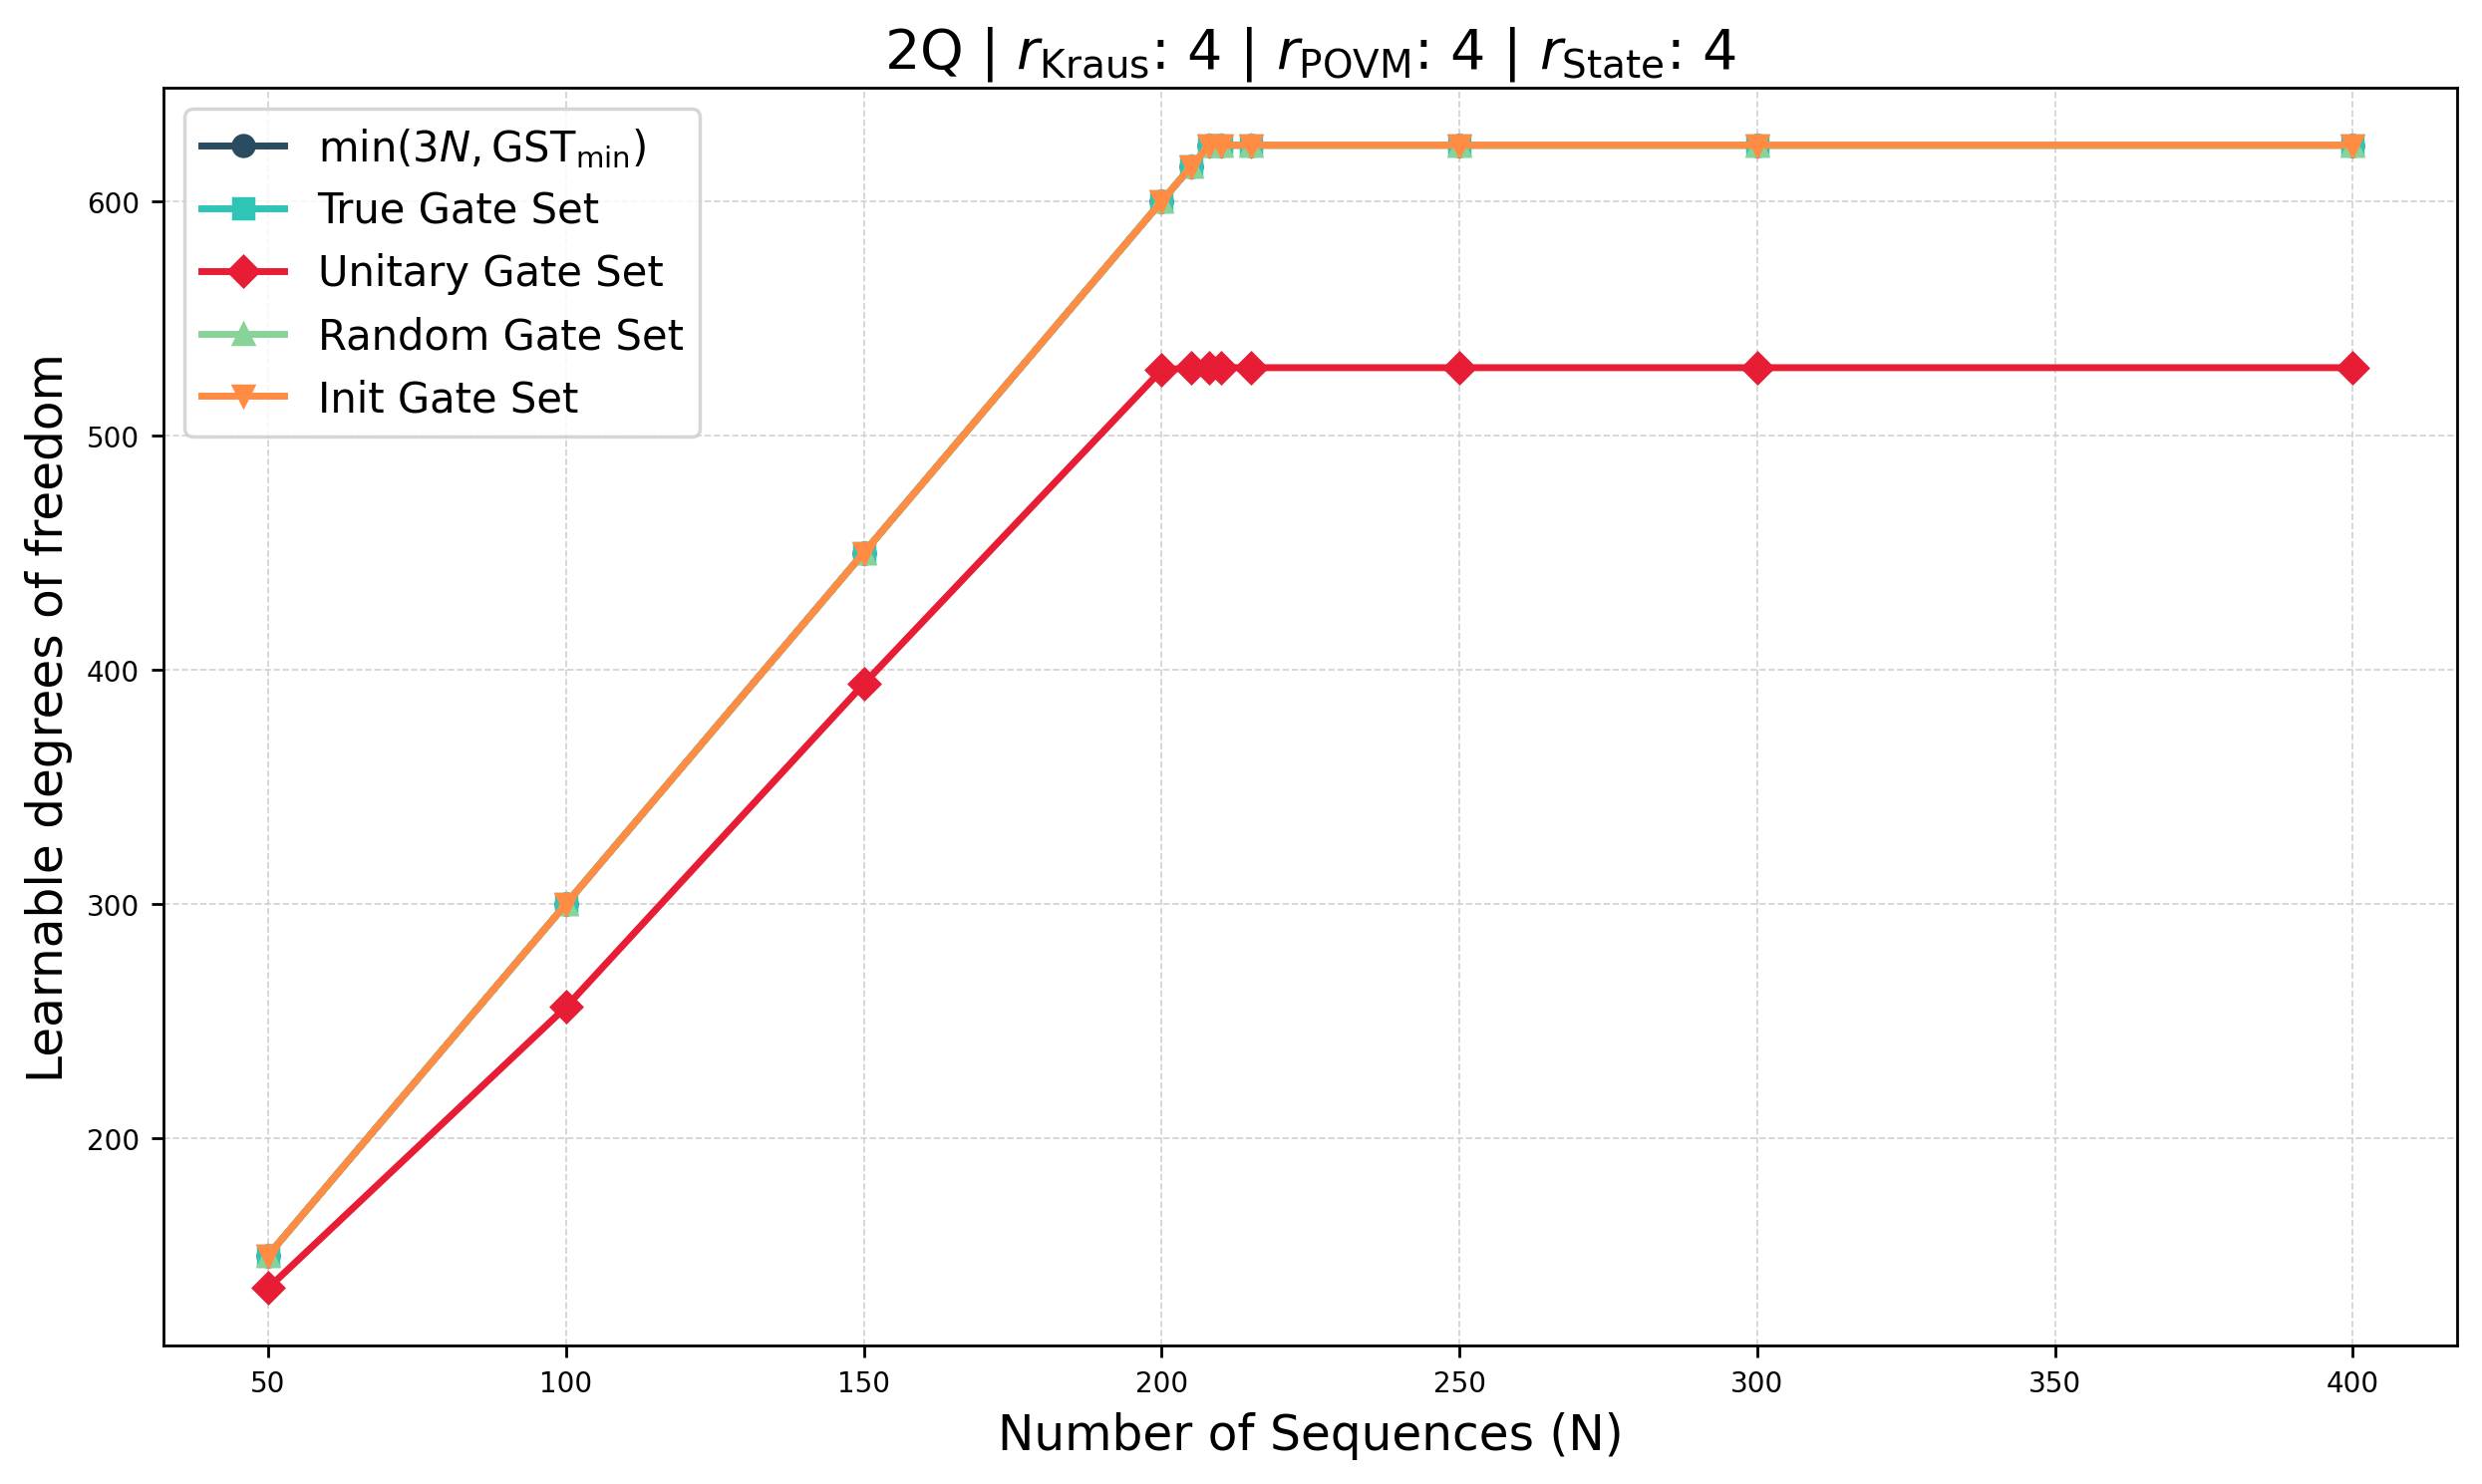

In [102]:
ranks_arrays = [ranks_expected, ranks_true_gate_set_1000_shots, ranks_unitary_gate_set_1000_shots, ranks_random_gate_set_1000_shots, ranks_init_gate_set_1000_shots]#ranks_rank_deficient_gate_set_1000_shots]

labels_array = [r"$\text{min}(3 N, \text{GST}_{\text{min}})$", "True Gate Set", "Unitary Gate Set", "Random Gate Set", "Init Gate Set"] #"Rank Deficient Gate Set"]

plot_cost_function(
    cost_array=ranks_arrays,
    labels=labels_array,
    x_array=number_of_sequences_list,
    use_semilogy=False,
    xlabel="Number of Sequences (N)",
    ylabel="Learnable degrees of freedom",
    title=title_general,
)

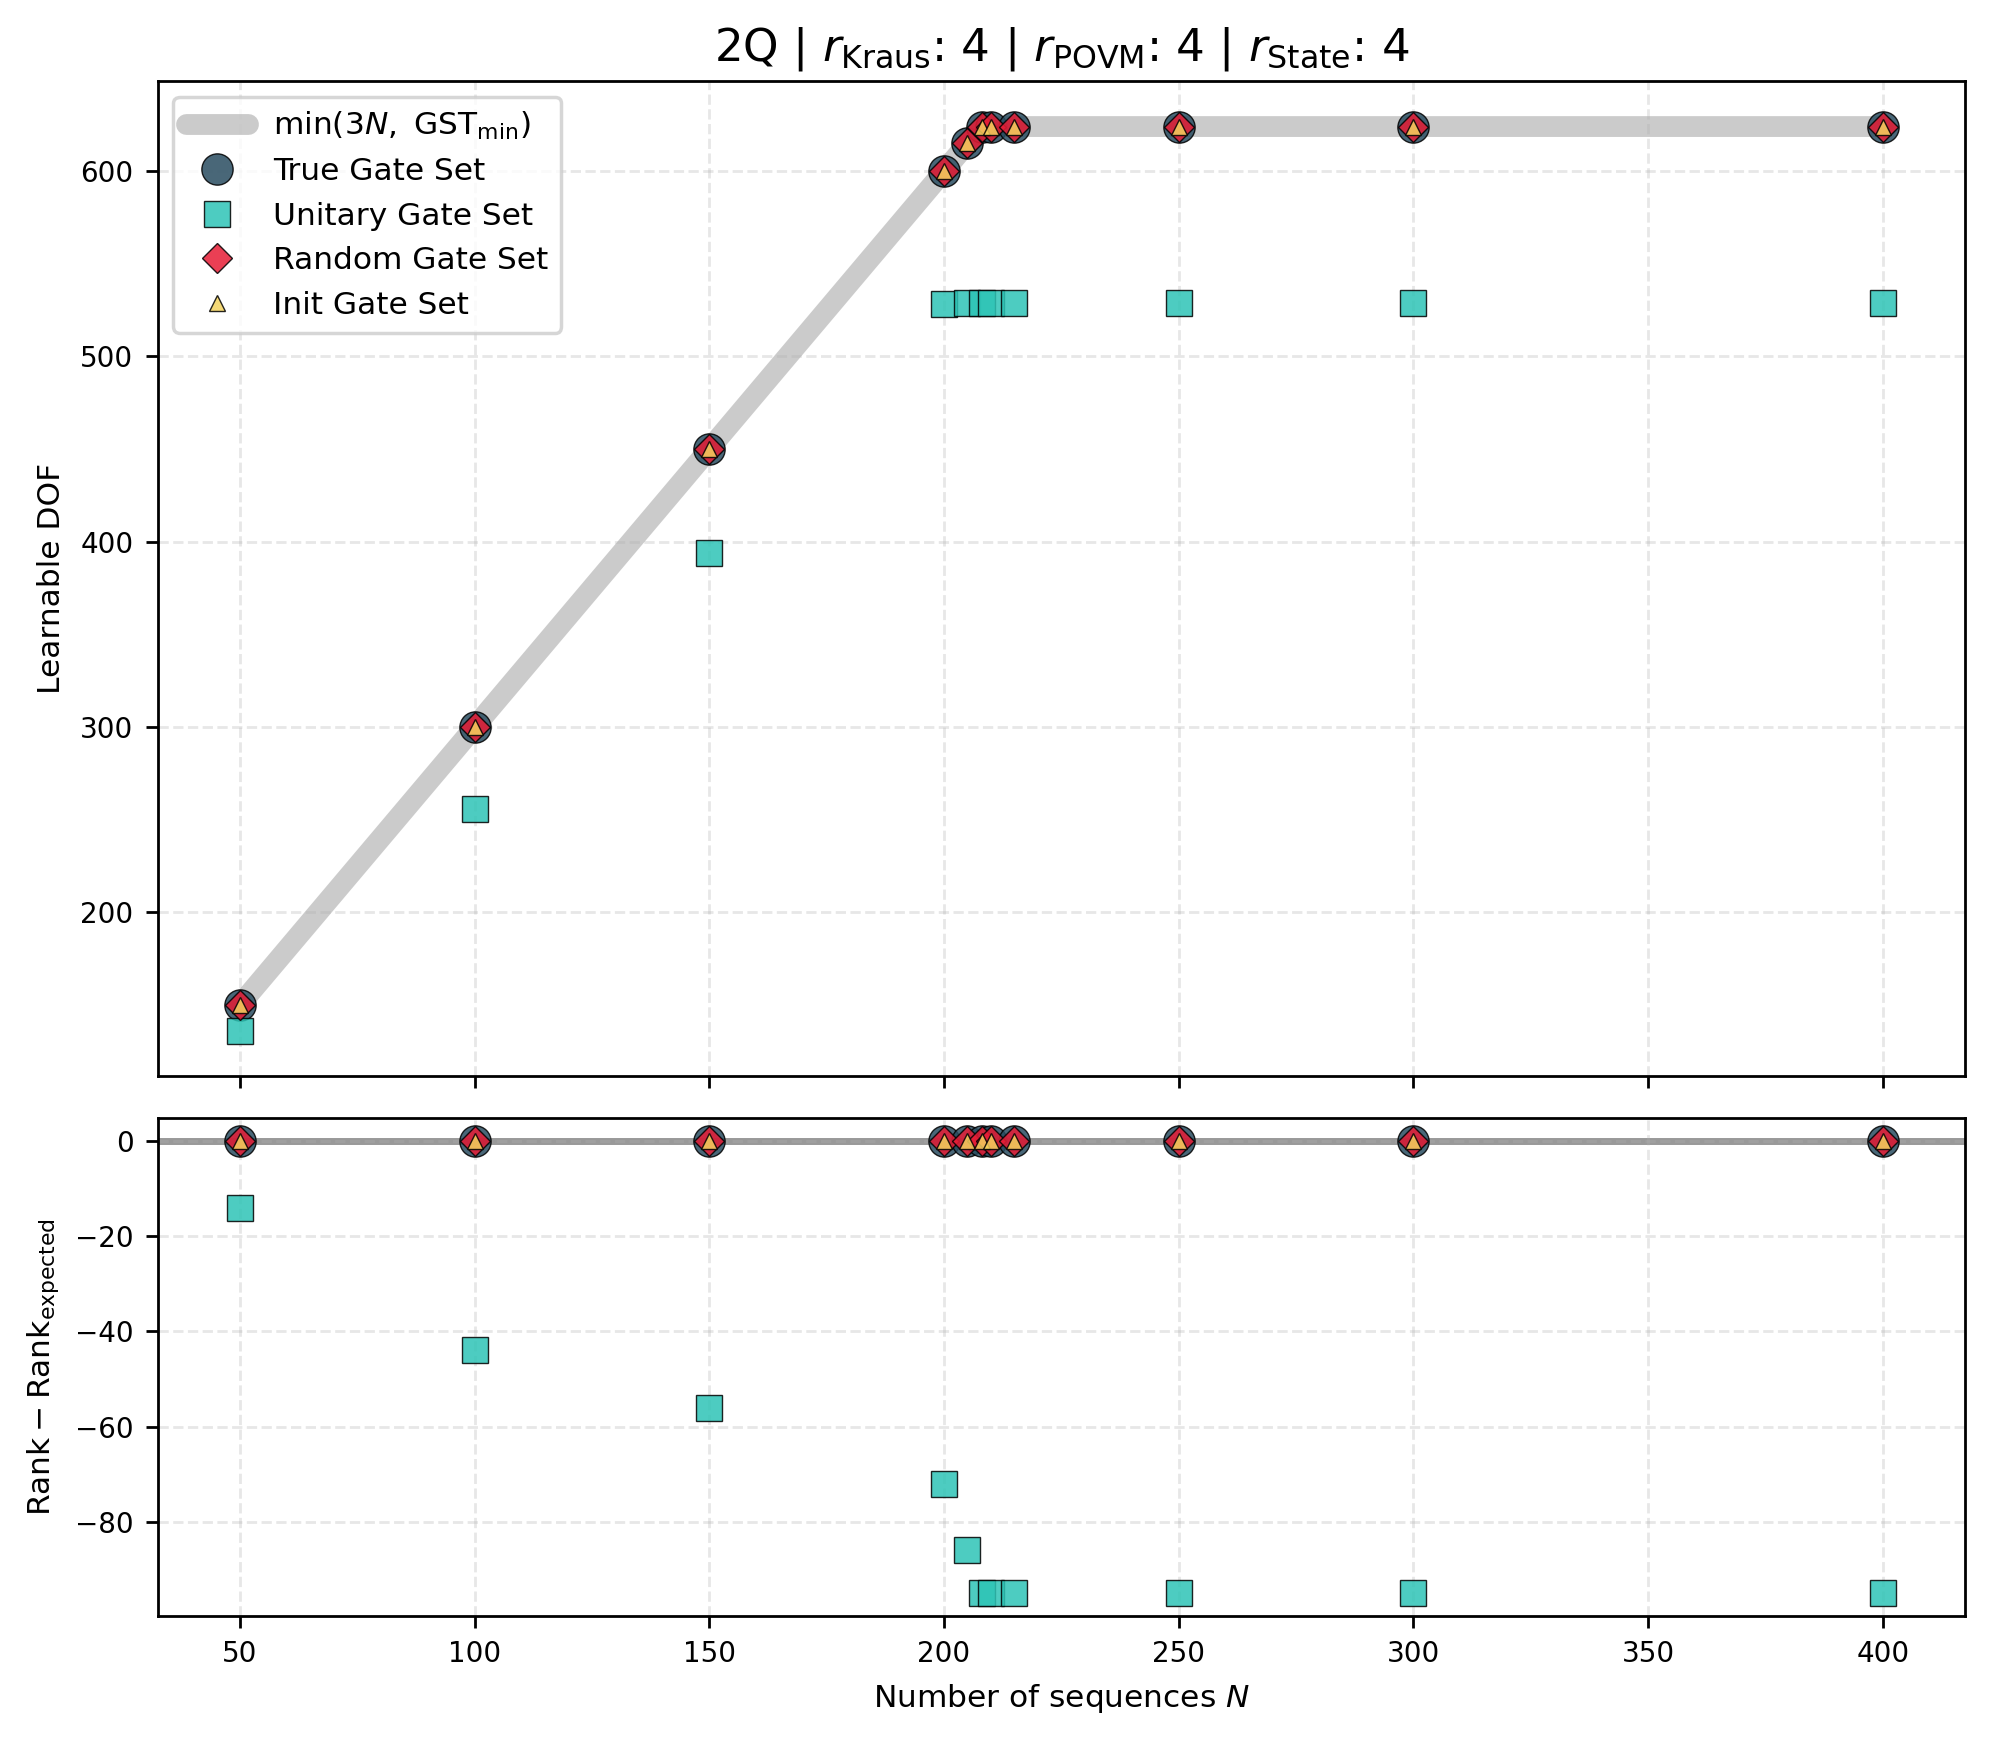

In [106]:
import matplotlib.pyplot as plt
from mGST.visualization import COLOUR_PALETTE, MARKERS

fig, (ax0, ax1) = plt.subplots(
    2, 1, figsize=(8, 7), dpi=250, sharex=True,
    gridspec_kw={"height_ratios": [2, 1]},
)

# Top: absolute ranks, expected drawn as a thick background guide
ax0.plot(number_of_sequences_list, ranks_expected, color="0.6", linewidth=6,
         alpha=0.5, solid_capstyle="round", label=r"$\min(3N,\ \mathrm{GST}_{\min})$", zorder=0)

for i, (ranks, label) in enumerate(zip(ranks_arrays[1:], labels_array[1:])):
    ax0.plot(number_of_sequences_list, ranks, linestyle="none",
             marker=MARKERS[i], markersize=9 - 1.5 * i, alpha=0.85,
             color=COLOUR_PALETTE[i], markeredgecolor="black",
             markeredgewidth=0.4, label=label)

ax0.set_ylabel("Learnable DOF")
ax0.set_title(title_general, fontsize=13)
ax0.grid(alpha=0.3, linestyle="--")
ax0.legend(fontsize=9)

# Bottom: residual w.r.t. the bound
ax1.axhline(0, color="0.6", linewidth=2, zorder=0)
for i, (ranks, label) in enumerate(zip(ranks_arrays[1:], labels_array[1:])):
    residual = [r - e for r, e in zip(ranks, ranks_expected)]
    ax1.plot(number_of_sequences_list, residual, linestyle="none",
             marker=MARKERS[i], markersize=9 - 1.5 * i, alpha=0.85,
             color=COLOUR_PALETTE[i], markeredgecolor="black", markeredgewidth=0.4)

ax1.set_xlabel("Number of sequences $N$")
ax1.set_ylabel(r"$\text{Rank} - \text{Rank}_{\mathrm{expected}}$")
ax1.grid(alpha=0.3, linestyle="--")
fig.tight_layout()

/var/folders/1z/5qqk4w_97cz44w7c72srsw2c0000gq/T/ipykernel_97311/1533072876.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


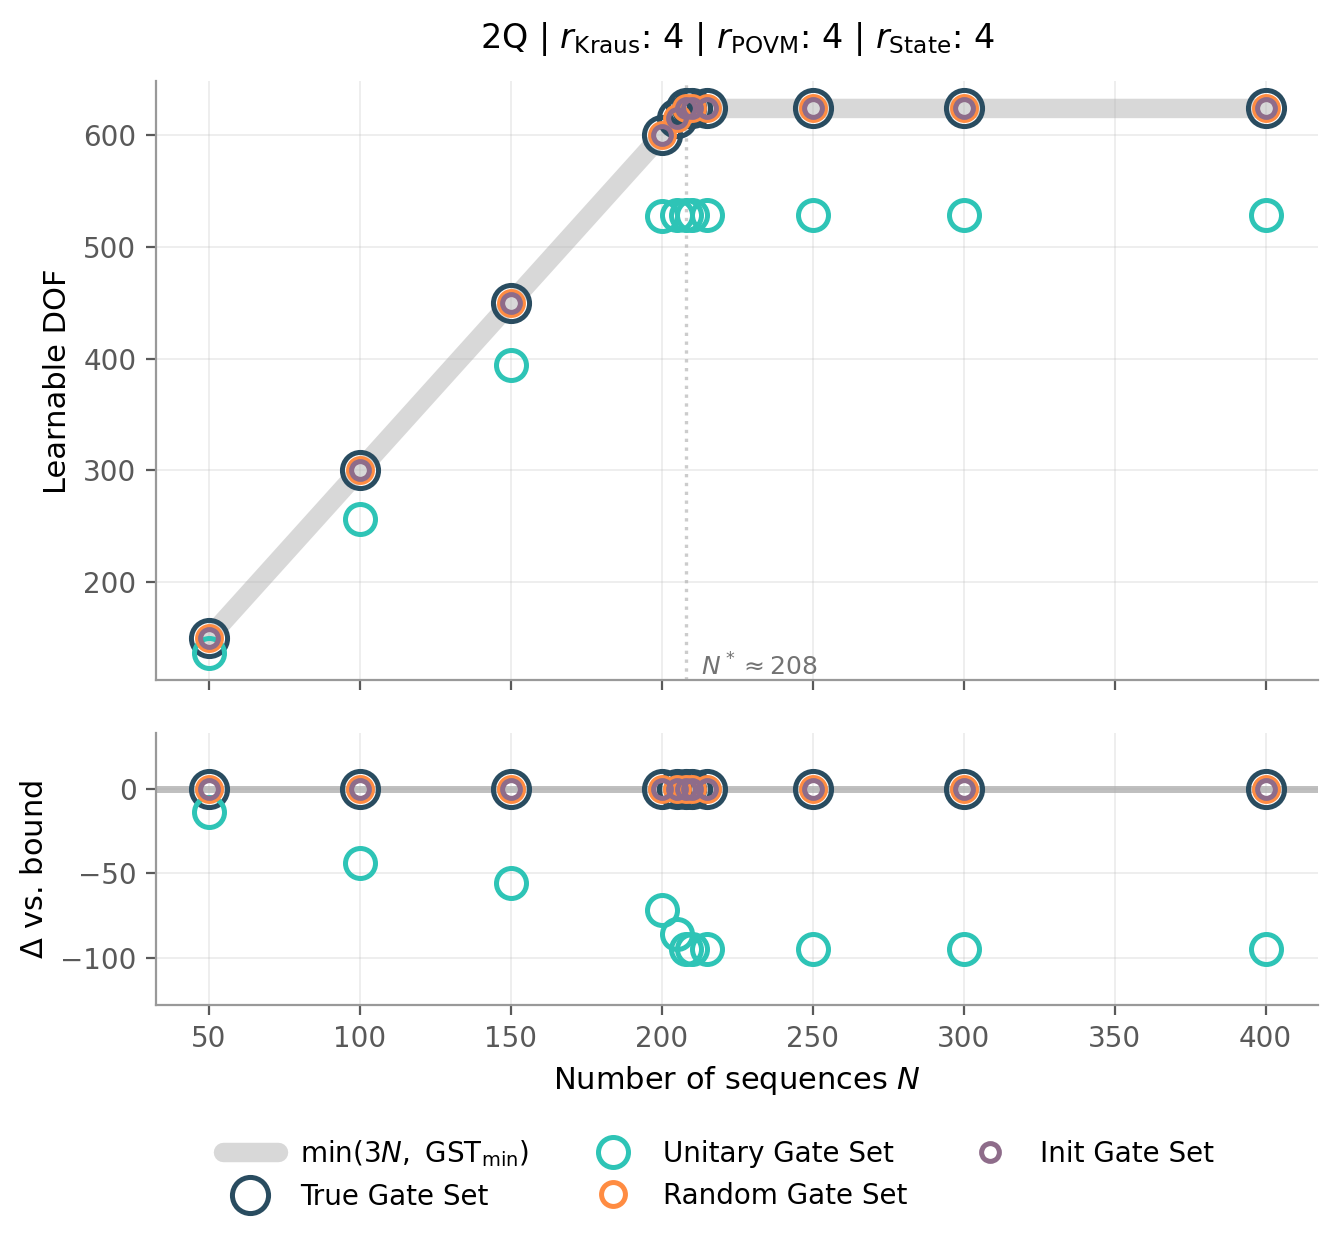

In [115]:
import matplotlib.pyplot as plt

# Ordered, harmonious subset instead of the full palette's clashing hues
SERIES_COLOURS = ["#294C60", "#2EC4B6", "#FF8C42", "#8E6C8A", "#4A4E69"]

series = list(zip(ranks_arrays[1:], labels_array[1:], SERIES_COLOURS))
n = len(series)

fig, (ax0, ax1) = plt.subplots(
    2, 1, figsize=(7.5, 6), dpi=200, sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1], "hspace": 0.12},
)

def draw(ax, values_fn):
    for i, (ranks, label, colour) in enumerate(series):
        ax.plot(
            number_of_sequences_list, values_fn(ranks),
            linestyle="none",
            marker="o",                      # one shape for everything
            markersize=13 - 2.2 * i,         # nested rings
            markerfacecolor="none",          # open markers -> all layers visible
            markeredgecolor=colour,
            markeredgewidth=1.8,
            label=label,
        )

ax0.plot(number_of_sequences_list, ranks_expected,
         color="0.75", linewidth=7, alpha=0.6, solid_capstyle="round",
         zorder=0, label=r"$\min(3N,\ \mathrm{GST}_{\min})$")
draw(ax0, lambda r: r)

ax1.axhline(0, color="0.75", linewidth=2.5, zorder=0)
draw(ax1, lambda r: [a - b for a, b in zip(r, ranks_expected)])

for ax in (ax0, ax1):
    ax.grid(alpha=0.25, linestyle="-", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("0.6")
    ax.spines["bottom"].set_color("0.6")
    ax.tick_params(colors="0.35", labelsize=10)

n_star = (min_expected + 1) / 3
ax0.axvline(n_star, color="0.8", linestyle=":", linewidth=1.2, zorder=0)
ax0.text(n_star, ax0.get_ylim()[0], rf"  $N^*\approx{n_star:.0f}$",
         va="bottom", fontsize=9, color="0.45")

ax0.set_ylabel("Learnable DOF", fontsize=11)
ax0.set_title(title_general, fontsize=12, pad=12)
ax1.set_ylabel(r"$\Delta$ vs. bound", fontsize=11)
ax1.set_xlabel("Number of sequences $N$", fontsize=11)
# ax1.set_yticks(range(min(0, min_expected + 50), 1))   # replace with an explicit integer range
ax1.margins(y=0.35)

handles, labels = ax0.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.02),
           ncol=3, frameon=False, fontsize=10)
fig.tight_layout()